<div style="background:linear-gradient(90deg,#c471ed,#f64f59);padding:26px;border-radius:14px;color:white">
<h4 style="margin:0;opacity:0.9">🧬 AI GENESIS · THE STORY OF AI, ONE ALGORITHM AT A TIME</h4>
<h1 style="margin:6px 0 4px 0">A* and Heuristic Search (1968)</h1>
<p style="margin:0">Search with a hint: Greedy Best-First · A* · IDA* · Weighted A*</p>
</div>

<br>

| 🪪 Quick card | |
|---|---|
| **Year** | 1968 |
| **Inventors** | Peter Hart, Nils Nilsson and Bertram Raphael (Stanford Research Institute) |
| **Family** | Symbolic AI → Search & Planning → **Informed (heuristic) search** |
| **Learns from data?** | ❌ No. It uses a hand-made "hint" function |
| **Builds on** | Dijkstra / Uniform-Cost Search (1956) |
| **Born for** | Shakey the robot, the first robot that planned its own actions |
| **Test problems** | Road map of Romania, the 8-puzzle, a maze |
| **Difficulty** | ⭐⭐⭐ Intermediate |

### 🎯 What you will learn in this notebook
1. Why blind search is not enough, and what a **heuristic** is
2. The magic formula **f(n) = g(n) + h(n)**
3. **Greedy Best-First**, **A\*** and **IDA\*** built from scratch
4. What makes a heuristic **admissible** and why that guarantees the best path
5. Two heuristics for the 8-puzzle, and the proof by experiment that the better one wins
6. The **effective branching factor**, a number that measures how good a heuristic is
7. **Weighted A\***: trading perfect answers for speed

## 📖 Part 1: The story

In the last story, blind search explored in every direction because it had **no idea where the goal was**. On the 8-puzzle, BFS examined 1,026 boards to solve a 12-move puzzle. The 15-puzzle has about 10 trillion states, so blind search is hopeless there.

### 🤖 Shakey the robot
At **Stanford Research Institute (SRI)**, researchers were building **Shakey** (1966 to 1972), a wheeled robot that could look at a room, decide a plan and push boxes around. Shakey needed to plan routes **quickly**, and Dijkstra's algorithm was too slow.

In **1968**, **Peter Hart, Nils Nilsson and Bertram Raphael** published the fix: take Uniform-Cost Search and add a **heuristic**, an educated guess of how far each state is from the goal. They proved that if the guess never *over*-estimates, the algorithm still finds the **optimal** path. They called it **A\*** (said "A-star").

### 🧭 Heuristic search before A\*
Just before, in **1966**, Doran and Michie's *Graph Traverser* used a heuristic to solve the 8-puzzle, always moving to the state that *looked* closest to the goal. That idea is today called **Greedy Best-First Search**: fast, but not always optimal.

### 👤 Who invented what

| Algorithm | Idea | Who and when |
|---|---|---|
| **Greedy Best-First** | Always go to the state that *looks* closest to the goal | Doran and Michie, 1966 |
| **A\*** | Cheapest total estimated cost, `g + h` | Hart, Nilsson, Raphael, 1968 |
| **IDA\*** | A\* with iterative deepening (tiny memory) | Richard Korf, 1985 |
| **Weighted A\*** | Trust the hint more, to go faster | Pohl, 1970 |

### 🗺️ Where this fits
```
Uninformed Search (1950s) → Informed Search: A* (1968) → Game Search: Minimax & Alpha-Beta → Constraint Satisfaction
```

## 🧠 Part 2: The ideas in plain words

You drive from Arad to Bucharest. At every town you ask two questions:

- **g(n): how far have I already driven?** (a known fact)
- **h(n): how far is it, in a straight line, from here to Bucharest?** (a **guess**, the *heuristic*)

| Algorithm | Which town does it expand next? | In one line |
|---|---|---|
| **Uniform-Cost** | smallest `g` | "Cheapest so far", ignores the goal |
| **Greedy Best-First** | smallest `h` | "Looks closest", ignores the past |
| **A\*** | smallest `g + h` | "Cheapest total trip", uses both ✨ |

### ➗ The formulas

$$f(n) = g(n) + h(n)$$

- `g(n)` = real cost from the start to `n`
- `h(n)` = estimated cost from `n` to the goal
- `f(n)` = estimated cost of the **best full path through** `n`

**Admissible heuristic:** `h(n)` never **over**-estimates the true remaining cost. A straight line is always shorter than or equal to any road, so straight-line distance is admissible.

$$0 \le h(n) \le h^{*}(n) \quad \text{(true cost to the goal)}$$

**Consistent heuristic:** `h(n) ≤ cost(n → n') + h(n')`. Like the triangle inequality: a detour can't make the guess drop faster than the real cost.

> ✅ **If `h` is admissible, A\* is guaranteed to return an optimal path.** Intuition: when A\* picks the goal, its `f` equals the true cost. If a cheaper path existed, some node on it would have a smaller `f` and would have been picked first.

### 🎚️ A whole family from one formula

| Algorithm | Priority | Special case |
|---|---|---|
| Uniform-Cost | `f = g` | `h = 0` |
| Greedy Best-First | `f = h` | ignore `g` |
| **A\*** | `f = g + h` | the balanced one |
| Weighted A\* | `f = g + w·h` | `w > 1` trusts the hint more |

## 🟣 Step 1: Import the libraries
> 💡 Same standard-library tools as before: `heapq` (priority queue), `deque` (queue), and `time`.

In [1]:
# Import the libraries we need
import heapq
import time
import itertools
import random
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch, FancyArrowPatch, Rectangle

# Styling and a colour palette used across the notebook
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
PINK, PURPLE, BLUE, GREEN, ORANGE, RED, GREY, DARK = "#f64f59", "#c471ed", "#2193b0", "#27ae60", "#f39c12", "#e74c3c", "#7f8c8d", "#2c3e50"

print("✅ Libraries ready!")

✅ Libraries ready!


## 🖼️ Step 2: Picture f = g + h
> 💡 To judge a town `n`, A\* adds **what we know** (the road already travelled, `g`) and **what we guess** (the remaining distance, `h`).

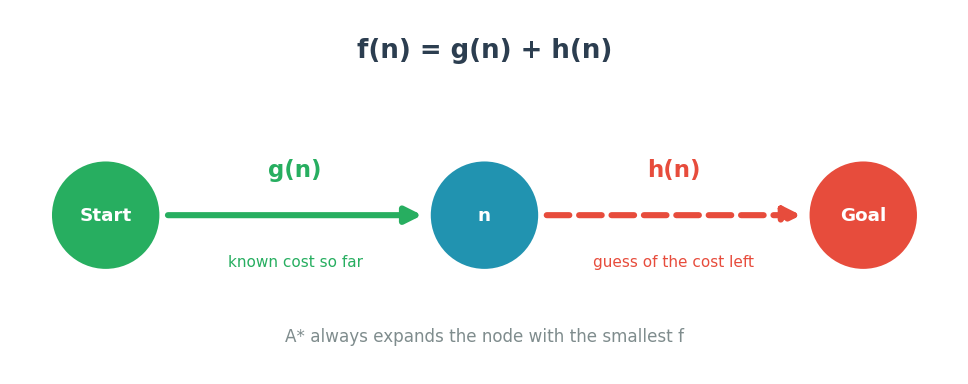

In [2]:
# Draw the idea behind f(n) = g(n) + h(n)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.set_xlim(0, 12); ax.set_ylim(0, 4.6); ax.set_aspect("equal"); ax.axis("off")

for x, label, color in [(1.2, "Start", GREEN), (6.0, "n", BLUE), (10.8, "Goal", RED)]:
    ax.add_patch(Circle((x, 2.0), 0.7, color=color, ec="white", lw=2, zorder=3))
    ax.text(x, 2.0, label, ha="center", va="center", color="white", fontweight="bold", fontsize=12, zorder=4)

ax.add_patch(FancyArrowPatch((1.95, 2.0), (5.25, 2.0), arrowstyle="-|>", mutation_scale=22, color=GREEN, lw=4))
ax.text(3.6, 2.5, "g(n)", ha="center", color=GREEN, fontsize=15, fontweight="bold")
ax.text(3.6, 1.35, "known cost so far", ha="center", color=GREEN, fontsize=10)

ax.add_patch(FancyArrowPatch((6.75, 2.0), (10.05, 2.0), arrowstyle="-|>", mutation_scale=22, color=RED, lw=4, ls="--"))
ax.text(8.4, 2.5, "h(n)", ha="center", color=RED, fontsize=15, fontweight="bold")
ax.text(8.4, 1.35, "guess of the cost left", ha="center", color=RED, fontsize=10)

ax.text(6.0, 4.0, "f(n) = g(n) + h(n)", ha="center", color=DARK, fontsize=17, fontweight="bold")
ax.text(6.0, 0.4, "A* always expands the node with the smallest f", ha="center", color=GREY, fontsize=11)
plt.tight_layout()
plt.show()

## 🧩 Step 3: The problems and the Romania map (again)
> 💡 These are the same problem classes as in the previous story, so this notebook stands on its own.
> New this time: for the Romania map we also have a **hint** for every city, the **straight-line distance to Bucharest** (in km).

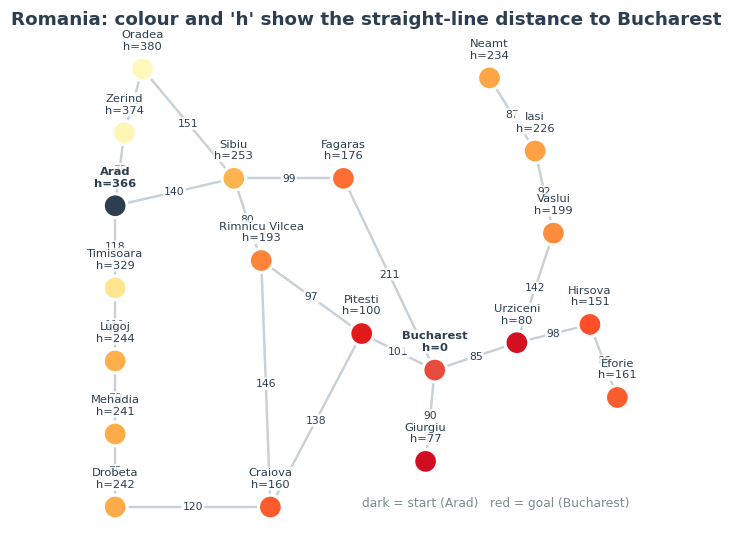

In [3]:
# Problem classes (same as the previous notebook)
class Problem:
    def __init__(self, start, goal):
        self.start, self.goal = start, goal
    def is_goal(self, state):
        return state == self.goal
    def successors(self, state):
        raise NotImplementedError

class MapProblem(Problem):
    def __init__(self, roads, start, goal):
        super().__init__(start, goal)
        self.roads = roads
    def successors(self, city):
        return [(f"go to {n}", n, km) for n, km in self.roads[city].items()]

class PuzzleProblem(Problem):
    MOVES = [("Up", -1, 0), ("Down", 1, 0), ("Left", 0, -1), ("Right", 0, 1)]
    def successors(self, state):
        blank = state.index(0)
        r, c = divmod(blank, 3)
        result = []
        for name, dr, dc in self.MOVES:
            nr, nc = r + dr, c + dc
            if 0 <= nr < 3 and 0 <= nc < 3:
                other = nr * 3 + nc
                s = list(state)
                s[blank], s[other] = s[other], s[blank]
                result.append((name, tuple(s), 1))
        return result

class GridProblem(Problem):
    MOVES = [("Up", -1, 0), ("Right", 0, 1), ("Down", 1, 0), ("Left", 0, -1)]
    def __init__(self, size, walls, start, goal):
        super().__init__(start, goal)
        self.size, self.walls = size, walls
    def successors(self, state):
        r, c = state
        result = []
        for name, dr, dc in self.MOVES:
            nr, nc = r + dr, c + dc
            if 0 <= nr < self.size and 0 <= nc < self.size and (nr, nc) not in self.walls:
                result.append((name, (nr, nc), 1))
        return result

# The road map of Romania (km)
edges = [("Arad", "Zerind", 75), ("Arad", "Sibiu", 140), ("Arad", "Timisoara", 118),
         ("Zerind", "Oradea", 71), ("Oradea", "Sibiu", 151), ("Timisoara", "Lugoj", 111),
         ("Lugoj", "Mehadia", 70), ("Mehadia", "Drobeta", 75), ("Drobeta", "Craiova", 120),
         ("Craiova", "Rimnicu Vilcea", 146), ("Craiova", "Pitesti", 138),
         ("Sibiu", "Fagaras", 99), ("Sibiu", "Rimnicu Vilcea", 80), ("Rimnicu Vilcea", "Pitesti", 97),
         ("Fagaras", "Bucharest", 211), ("Pitesti", "Bucharest", 101), ("Bucharest", "Giurgiu", 90),
         ("Bucharest", "Urziceni", 85), ("Urziceni", "Hirsova", 98), ("Hirsova", "Eforie", 86),
         ("Urziceni", "Vaslui", 142), ("Vaslui", "Iasi", 92), ("Iasi", "Neamt", 87)]
roads = {}
for a, b, km in edges:
    roads.setdefault(a, {})[b] = km
    roads.setdefault(b, {})[a] = km

# The hint: straight-line distance from every city to Bucharest (km)
straight_line = {"Arad": 366, "Bucharest": 0, "Craiova": 160, "Drobeta": 242, "Eforie": 161, "Fagaras": 176,
                 "Giurgiu": 77, "Hirsova": 151, "Iasi": 226, "Lugoj": 244, "Mehadia": 241, "Neamt": 234,
                 "Oradea": 380, "Pitesti": 100, "Rimnicu Vilcea": 193, "Sibiu": 253, "Timisoara": 329,
                 "Urziceni": 80, "Vaslui": 199, "Zerind": 374}

pos = {"Oradea": (90, 450), "Zerind": (70, 380), "Arad": (60, 300), "Timisoara": (60, 210), "Lugoj": (60, 130),
       "Mehadia": (60, 50), "Drobeta": (60, -30), "Craiova": (230, -30), "Sibiu": (190, 330),
       "Rimnicu Vilcea": (220, 240), "Fagaras": (310, 330), "Pitesti": (330, 160), "Bucharest": (410, 120),
       "Giurgiu": (400, 20), "Urziceni": (500, 150), "Hirsova": (580, 170), "Eforie": (610, 90),
       "Vaslui": (540, 270), "Iasi": (520, 360), "Neamt": (470, 440)}

def draw_map(path=None, title="", color=RED, show_h=False):
    fig, ax = plt.subplots(figsize=(8.5, 6))
    on_path = set(zip(path[:-1], path[1:])) | set(zip(path[1:], path[:-1])) if path else set()
    for a, b, km in edges:
        (x1, y1), (x2, y2) = pos[a], pos[b]
        hot = (a, b) in on_path
        ax.plot([x1, x2], [y1, y2], color=color if hot else "#c8d0d8", lw=4.5 if hot else 1.6, zorder=1)
        ax.text((x1 + x2) / 2, (y1 + y2) / 2, str(km), fontsize=7, color=DARK, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.9), zorder=2)
    for city, (x, y) in pos.items():
        in_path = bool(path) and city in path
        if show_h:
            face = plt.cm.YlOrRd_r(straight_line[city] / 400) if city not in ("Arad", "Bucharest") else (DARK if city == "Arad" else RED)
        else:
            face = DARK if city == "Arad" else RED if city == "Bucharest" else color if in_path else BLUE
        ax.add_patch(Circle((x, y), 13, color=face, ec=color if (in_path and show_h) else "white", lw=3 if (in_path and show_h) else 2, zorder=3))
        label = f"{city}\nh={straight_line[city]}" if show_h else city
        ax.text(x, y + (31 if show_h else 25), label, fontsize=7.5, ha="center", va="center", color=DARK,
                fontweight="bold" if (city in ("Arad", "Bucharest") or in_path) else None,
                bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.85), zorder=4)
    ax.text(330, -30, "dark = start (Arad)   red = goal (Bucharest)", fontsize=8, color=GREY)
    ax.set_title(title, color=DARK, fontweight="bold")
    ax.set_aspect("equal"); ax.axis("off")
    plt.show()

draw_map(title="Romania: colour and 'h' show the straight-line distance to Bucharest", show_h=True)

## 🛠️ Step 4: Helpers, plus BFS and UCS for comparison
> 💡 The same answer format as before (path, cost, nodes expanded, memory, time). We also add:
> - `generated`: how many states were discovered (used later for the *effective branching factor*)
> - `trace`: a step-by-step record (state, g, h, f) so we can watch A\* think
>
> BFS and UCS are copied from the previous notebook as our baselines.

In [4]:
# Helpers shared by all algorithms
def reconstruct(parent, goal_state):
    path, s = [], goal_state
    while s is not None:
        path.append(s)
        s = parent[s]
    return path[::-1]

def path_cost(problem, path):
    return sum(min(c for _, n, c in problem.successors(a) if n == b) for a, b in zip(path[:-1], path[1:]))

def finish(name, problem, path, expanded, memory, generated, t0, order=None, trace=None):
    return {"algorithm": name, "found": path is not None, "path": path,
            "steps": len(path) - 1 if path else None,
            "cost": path_cost(problem, path) if path else None,
            "expanded": expanded, "memory": memory, "generated": generated,
            "ms": round((time.perf_counter() - t0) * 1000, 1), "order": order or [], "trace": trace or []}

def results_table(results):
    return pd.DataFrame([{k: r[k] for k in ["algorithm", "found", "steps", "cost", "expanded", "memory", "ms"]}
                         for r in results])

# --- Baseline 1: Breadth-First Search (unit costs) ---
def bfs(problem):
    t0 = time.perf_counter()
    frontier, parent, order, expanded = deque([problem.start]), {problem.start: None}, [], 0
    if problem.is_goal(problem.start):
        return finish("BFS", problem, [problem.start], 0, 1, 1, t0)
    while frontier:
        state = frontier.popleft()
        order.append(state); expanded += 1
        for _, nxt, _ in problem.successors(state):
            if nxt not in parent:
                parent[nxt] = state
                if problem.is_goal(nxt):
                    return finish("BFS", problem, reconstruct(parent, nxt), expanded, len(parent), len(parent), t0, order)
                frontier.append(nxt)
    return finish("BFS", problem, None, expanded, len(parent), len(parent), t0, order)

# --- Baseline 2: Uniform-Cost Search ---
def ucs(problem):
    t0 = time.perf_counter()
    counter = itertools.count()
    heap, explored, parent, order, expanded, peak = [(0, next(counter), problem.start, None)], set(), {}, [], 0, 1
    seen = {problem.start}
    while heap:
        cost, _, state, par = heapq.heappop(heap)
        if state in explored:
            continue
        explored.add(state); parent[state] = par
        order.append(state); expanded += 1
        if problem.is_goal(state):
            return finish("UCS", problem, reconstruct(parent, state), expanded, peak, len(seen), t0, order)
        for _, nxt, step in problem.successors(state):
            if nxt not in explored:
                seen.add(nxt)
                heapq.heappush(heap, (cost + step, next(counter), nxt, state))
        peak = max(peak, len(heap) + len(explored))
    return finish("UCS", problem, None, expanded, peak, len(seen), t0, order)

map_problem = MapProblem(roads, "Arad", "Bucharest")
h_map = lambda city: straight_line[city]       # our hint for the map

r_ucs = ucs(map_problem)
print(f"UCS on Romania: {' → '.join(r_ucs['path'])} | {r_ucs['cost']} km | expanded {r_ucs['expanded']} cities")

UCS on Romania: Arad → Sibiu → Rimnicu Vilcea → Pitesti → Bucharest | 418 km | expanded 13 cities


## 🏃 Step 5: Greedy Best-First Search
> 💡 Priority = `h(n)` only. Always expand the state that **looks** closest to the goal.
> It is fast because it heads straight at the goal. But it ignores the distance already travelled, so it can be fooled into a longer route.

In [5]:
# Greedy Best-First Search: priority = h(n)
def greedy(problem, h):
    t0 = time.perf_counter()
    counter = itertools.count()
    heap = [(h(problem.start), next(counter), problem.start, None)]
    explored, parent, seen = set(), {}, {problem.start}
    order, trace, expanded, peak = [], [], 0, 1
    while heap:
        _, _, state, par = heapq.heappop(heap)
        if state in explored:
            continue
        explored.add(state); parent[state] = par
        order.append(state); expanded += 1
        trace.append((state, None, h(state), h(state)))
        if problem.is_goal(state):
            return finish("Greedy", problem, reconstruct(parent, state), expanded, peak, len(seen), t0, order, trace)
        for _, nxt, _ in problem.successors(state):
            if nxt not in explored:
                seen.add(nxt)
                heapq.heappush(heap, (h(nxt), next(counter), nxt, state))
        peak = max(peak, len(heap) + len(explored))
    return finish("Greedy", problem, None, expanded, peak, len(seen), t0, order, trace)

r_greedy = greedy(map_problem, h_map)
print(f"Greedy on Romania: {' → '.join(r_greedy['path'])} | {r_greedy['cost']} km | expanded {r_greedy['expanded']} cities")

Greedy on Romania: Arad → Sibiu → Fagaras → Bucharest | 450 km | expanded 4 cities


## ⭐ Step 6: A\* Search
> 💡 Priority = `f(n) = g(n) + h(n)`. We keep `best_g[state]`, the cheapest known cost to reach each state. If we find a cheaper way to a state we already knew, we update it.
> The goal test happens when a node is **taken out** of the queue, like in UCS. That is what keeps the answer optimal.
> `weight` is for later (Weighted A\*). With the default `weight=1` this is classic A\*.

In [6]:
# A* Search (weight = 1) and Weighted A* (weight > 1)
def astar(problem, h, weight=1, name="A*"):
    t0 = time.perf_counter()
    counter = itertools.count()
    best_g = {problem.start: 0}
    parent = {problem.start: None}
    heap = [(weight * h(problem.start), next(counter), 0, problem.start)]
    order, trace, expanded, peak = [], [], 0, 1
    done = set()
    while heap:
        f, _, g, state = heapq.heappop(heap)
        if state in done or g > best_g[state]:            # an outdated entry
            continue
        done.add(state)
        order.append(state); expanded += 1
        trace.append((state, g, h(state), g + h(state)))
        if problem.is_goal(state):
            return finish(name, problem, reconstruct(parent, state), expanded, peak, len(best_g), t0, order, trace)
        for _, nxt, step in problem.successors(state):
            new_g = g + step
            if new_g < best_g.get(nxt, float("inf")):     # found a cheaper way to nxt
                best_g[nxt] = new_g
                parent[nxt] = state
                done.discard(nxt)
                heapq.heappush(heap, (new_g + weight * h(nxt), next(counter), new_g, nxt))
        peak = max(peak, len(heap) + len(done))
    return finish(name, problem, None, expanded, peak, len(best_g), t0, order, trace)

r_astar = astar(map_problem, h_map)
print(f"A* on Romania: {' → '.join(r_astar['path'])} | {r_astar['cost']} km | expanded {r_astar['expanded']} cities")

A* on Romania: Arad → Sibiu → Rimnicu Vilcea → Pitesti → Bucharest | 418 km | expanded 6 cities


## 🔎 Step 7: Watch A\* think
> 💡 This table is A\*'s diary, in the order it expanded the cities. At every step it picks the **smallest f**.
> Look at how it first explores Fagaras (`f = 415`) but then finds Pitesti (`f = 417`) leads to a **cheaper total** than the goal reached through Fagaras (`450`). A greedy search would have rushed ahead.

In [7]:
# Show A*'s step-by-step diary on the Romania map
diary = pd.DataFrame(r_astar["trace"], columns=["city expanded", "g (km so far)", "h (hint)", "f = g + h"])
diary.index = range(1, len(diary) + 1)
diary.index.name = "step"
diary

,city expanded,g (km so far),h (hint),f = g + h
step,,,,
1,Arad,0,366,366
2,Sibiu,140,253,393
3,Rimnicu Vilcea,220,193,413
4,Fagaras,239,176,415
5,Pitesti,317,100,417
6,Bucharest,418,0,418


## 🏁 Step 8: Who found the best route?
> 💡 Compare four searches on the same trip:
> - **UCS** is optimal but expanded the most cities (blind).
> - **Greedy** expanded few cities, but the route is **not the shortest**.
> - **A\*** is optimal **and** expands far fewer cities than UCS.

algorithm  distance (km)  cities expanded                                               route
      UCS            418               13 Arad → Sibiu → Rimnicu Vilcea → Pitesti → Bucharest
   Greedy            450                4                  Arad → Sibiu → Fagaras → Bucharest
       A*            418                6 Arad → Sibiu → Rimnicu Vilcea → Pitesti → Bucharest


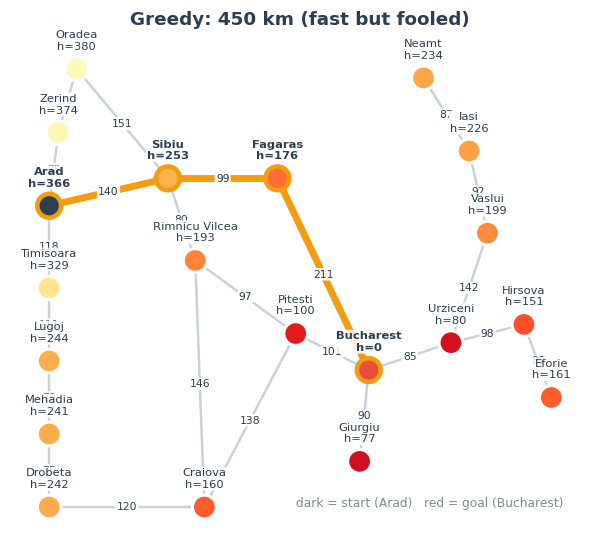

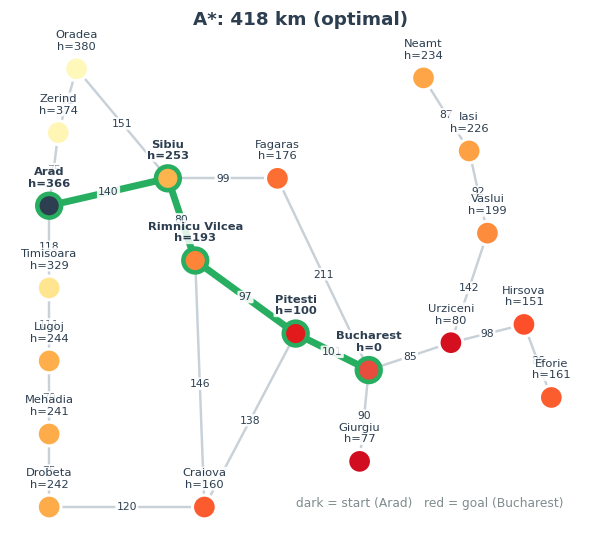

In [8]:
# Compare UCS, Greedy and A* on the Romania map
rows = []
for r in (r_ucs, r_greedy, r_astar):
    rows.append({"algorithm": r["algorithm"], "distance (km)": r["cost"], "cities expanded": r["expanded"],
                 "route": " → ".join(r["path"])})
print(pd.DataFrame(rows).to_string(index=False))

draw_map(r_greedy["path"], f"Greedy: {r_greedy['cost']} km (fast but fooled)", ORANGE, show_h=True)
draw_map(r_astar["path"], f"A*: {r_astar['cost']} km (optimal)", GREEN, show_h=True)

## 🔁 Step 9: IDA\*, A\* with tiny memory
> 💡 A\* must remember **every** state it has seen, which can fill the memory. **IDA\*** (Iterative Deepening A\*) fixes this using the idea from the previous notebook:
> run a depth-first search, but cut off any branch whose `f = g + h` is above a **threshold**. If nothing is found, raise the threshold to the smallest `f` that was cut off, and try again.
> It stores only the current path, so memory is tiny.

In [9]:
# IDA*: depth-first search limited by f = g + h
def ida_star(problem, h):
    t0 = time.perf_counter()
    path, on_path = [problem.start], {problem.start}
    stats = {"expanded": 0, "peak": 1}
    FOUND = "found"

    def search(g, bound):
        node = path[-1]
        f = g + h(node)
        if f > bound:
            return f                                   # cut off: report the f that exceeded the bound
        if problem.is_goal(node):
            return FOUND
        stats["expanded"] += 1
        smallest = float("inf")
        for _, nxt, step in problem.successors(node):
            if nxt in on_path:                         # don't walk in a circle
                continue
            path.append(nxt); on_path.add(nxt)
            stats["peak"] = max(stats["peak"], len(path))
            result = search(g + step, bound)
            if result == FOUND:
                return FOUND
            smallest = min(smallest, result)
            path.pop(); on_path.discard(nxt)
        return smallest

    bound = h(problem.start)
    while True:
        result = search(0, bound)
        if result == FOUND:
            return finish("IDA*", problem, list(path), stats["expanded"], stats["peak"], stats["expanded"], t0)
        if result == float("inf"):
            return finish("IDA*", problem, None, stats["expanded"], stats["peak"], stats["expanded"], t0)
        bound = result                                  # raise the threshold

r_ida = ida_star(map_problem, h_map)
print(f"IDA* on Romania: {' → '.join(r_ida['path'])} | {r_ida['cost']} km | memory = {r_ida['memory']} cities on the path")

IDA* on Romania: Arad → Sibiu → Rimnicu Vilcea → Pitesti → Bucharest | 418 km | memory = 5 cities on the path


## 🔢 Step 10: Hints for the 8-puzzle
> 💡 For the puzzle there is no straight line, so we invent two heuristics. Both are **relaxations**: they count the cost of an *easier* version of the puzzle.
>
> | Heuristic | Idea | Why it never over-estimates |
> |---|---|---|
> | **h1: misplaced tiles** | count tiles that are not in their goal square | every misplaced tile needs at least 1 move |
> | **h2: Manhattan distance** | for each tile, rows + columns away from its goal square, summed | each move shifts one tile by one square |
>
> Manhattan distance is always **at least** as big as misplaced tiles, so it is **more informed** (*h2 dominates h1*). In a perfect world a bigger (but still admissible) heuristic means fewer nodes expanded.

In [10]:
# The two 8-puzzle heuristics and a worked example
GOAL = (1, 2, 3, 4, 5, 6, 7, 8, 0)
START = (1, 6, 3, 4, 0, 5, 7, 2, 8)
goal_pos = {tile: divmod(i, 3) for i, tile in enumerate(GOAL)}

def h_misplaced(state):
    return sum(1 for i, t in enumerate(state) if t != 0 and t != GOAL[i])

def h_manhattan(state):
    total = 0
    for i, t in enumerate(state):
        if t != 0:
            r, c = divmod(i, 3)
            gr, gc = goal_pos[t]
            total += abs(r - gr) + abs(c - gc)
    return total

# Per-tile breakdown for the start board
rows = []
for i, t in enumerate(START):
    if t != 0:
        r, c = divmod(i, 3); gr, gc = goal_pos[t]
        rows.append({"tile": t, "now at (row, col)": (r, c), "goal at": (gr, gc),
                     "misplaced?": int(t != GOAL[i]), "Manhattan distance": abs(r - gr) + abs(c - gc)})
tiles = pd.DataFrame(rows)
print(f"Start board: {START[:3]} / {START[3:6]} / {START[6:]}   (0 = blank)")
print(f"h1 (misplaced tiles) = {h_misplaced(START)}   |   h2 (Manhattan) = {h_manhattan(START)}   |   true cost = 12")
print("Both are below 12, so both are admissible.\n")
tiles

Start board: (1, 6, 3) / (4, 0, 5) / (7, 2, 8)   (0 = blank)
h1 (misplaced tiles) = 4   |   h2 (Manhattan) = 6   |   true cost = 12
Both are below 12, so both are admissible.



,tile,"now at (row, col)",goal at,misplaced?,Manhattan distance
0,1,"(0, 0)","(0, 0)",0,0
1,6,"(0, 1)","(1, 2)",1,2
2,3,"(0, 2)","(0, 2)",0,0
3,4,"(1, 0)","(1, 0)",0,0
4,5,"(1, 2)","(1, 1)",1,1
5,7,"(2, 0)","(2, 0)",0,0
6,2,"(2, 1)","(0, 1)",1,2
7,8,"(2, 2)","(2, 1)",1,1


## 🏎️ Step 11: The race on the 8-puzzle
> 💡 The same 12-move puzzle as in the previous story, where BFS expanded **1,026** boards.
> Check the **steps** column. Only Greedy may return a longer solution than 12. Check **expanded**: the hint makes a huge difference.

        algorithm  found  steps  cost  expanded  memory  ms
              BFS   True     12    12      1026    1639 5.0
      Greedy (h2)   True     22    22       104     174 2.5
A* (h1 misplaced)   True     12    12       154     256 2.6
A* (h2 Manhattan)   True     12    12        79     132 1.9
        IDA* (h2)   True     12    12        72      13 1.1


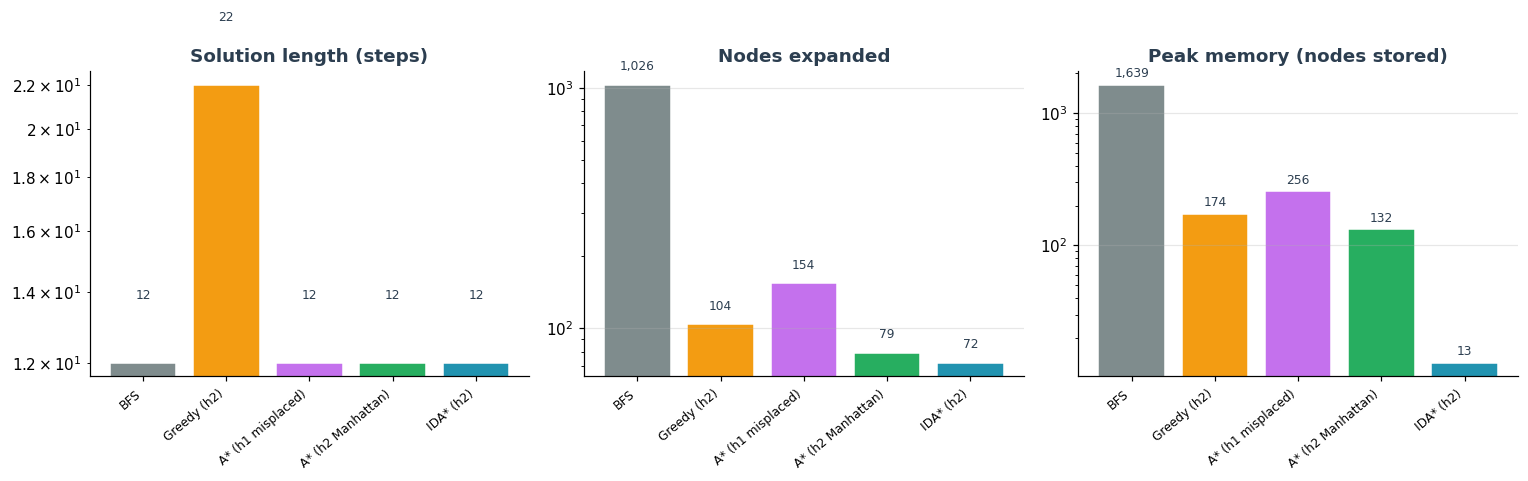

In [11]:
# Run every algorithm on the 8-puzzle start board
puzzle = PuzzleProblem(START, GOAL)
race = [bfs(puzzle),
        greedy(puzzle, h_manhattan),
        astar(puzzle, h_misplaced, name="A* (h1 misplaced)"),
        astar(puzzle, h_manhattan, name="A* (h2 Manhattan)"),
        ida_star(puzzle, h_manhattan)]
race[1]["algorithm"] = "Greedy (h2)"
race[4]["algorithm"] = "IDA* (h2)"
print(results_table(race).to_string(index=False))

names = [r["algorithm"] for r in race]
palette = [GREY, ORANGE, PURPLE, GREEN, BLUE]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, key, title in zip(axes, ["steps", "expanded", "memory"],
                          ["Solution length (steps)", "Nodes expanded", "Peak memory (nodes stored)"]):
    values = [r[key] for r in race]
    bars = ax.bar(range(len(names)), values, color=palette, edgecolor="white")
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=40, ha="right", fontsize=8)
    ax.set_yscale("log")
    ax.set_title(title, color=DARK, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)
    for bar, v in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, v * 1.15, f"{v:,}", ha="center", fontsize=8, color=DARK)
plt.tight_layout()
plt.show()

## 🧪 Step 12: Is a better heuristic really better? A real experiment
> 💡 One puzzle is just a story. Let's gather **32 random puzzles** in four difficulty levels (solution length around 5, 9, 13 and 17 moves), solve each with BFS, A\*(h1) and A\*(h2), and **average** the number of expanded nodes.
> We also compute the **effective branching factor `b*`**: the branching factor a uniform tree would need to contain all the nodes generated. Closer to **1** = the heuristic is sharper. This takes a few seconds.

difficulty  puzzles  BFS expanded  BFS b*  A*(h1) expanded  A*(h1) b*  A*(h2) expanded  A*(h2) b*
 ≈ 5 moves        8            43    1.89               10       1.36                8       1.31
 ≈ 9 moves        8           233    1.74               23       1.28               13       1.17
≈ 13 moves        8          1633    1.72              132       1.36               34       1.19
≈ 17 moves        8         11918    1.68             1081       1.44              252       1.30


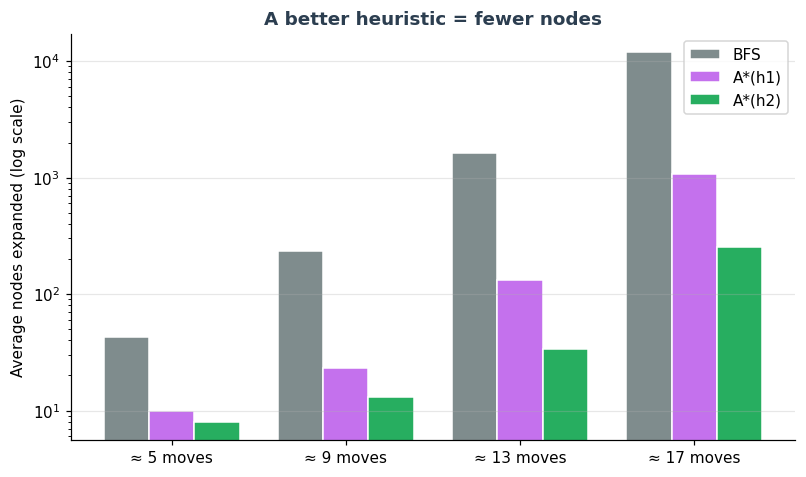

In [12]:
# Collect random puzzles by difficulty, then compare BFS, A*(h1) and A*(h2)
def effective_branching(generated, depth):
    # solve  generated + 1 = 1 + b + b^2 + ... + b^depth  for b (bisection)
    if depth == 0:
        return 1.0
    low, high = 1.0, 10.0
    for _ in range(60):
        mid = (low + high) / 2
        total = sum(mid ** k for k in range(depth + 1))
        low, high = (mid, high) if total < generated + 1 else (low, mid)
    return (low + high) / 2

rng = random.Random(1)
bins = {"≈ 5 moves": (4, 6), "≈ 9 moves": (8, 10), "≈ 13 moves": (12, 14), "≈ 17 moves": (16, 18)}
collected = {name: [] for name in bins}
attempts = 0
while attempts < 1500 and any(len(v) < 8 for v in collected.values()):
    attempts += 1
    state, previous = GOAL, None
    for _ in range(rng.randint(6, 45)):                     # scramble by random legal moves (always solvable)
        options = [n for _, n, _ in PuzzleProblem(state, GOAL).successors(state) if n != previous]
        previous, state = state, rng.choice(options)
    depth = astar(PuzzleProblem(state, GOAL), h_manhattan)["steps"]
    for name, (lo, hi) in bins.items():
        if lo <= depth <= hi and len(collected[name]) < 8:
            collected[name].append(state)

summary = []
for name, states in collected.items():
    stats = {"BFS": [], "A*(h1)": [], "A*(h2)": []}
    depths = []
    for st in states:
        p = PuzzleProblem(st, GOAL)
        for key, r in (("BFS", bfs(p)), ("A*(h1)", astar(p, h_misplaced)), ("A*(h2)", astar(p, h_manhattan))):
            stats[key].append((r["expanded"], effective_branching(r["generated"], r["steps"])))
        depths.append(r["steps"])
    row = {"difficulty": name, "puzzles": len(states)}
    for key, values in stats.items():
        row[f"{key} expanded"] = round(np.mean([v[0] for v in values]))
        row[f"{key} b*"] = round(np.mean([v[1] for v in values]), 2)
    summary.append(row)

experiment = pd.DataFrame(summary)
print(experiment.to_string(index=False))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
x = np.arange(len(experiment)); w = 0.26
for k, (key, color) in enumerate([("BFS", GREY), ("A*(h1)", PURPLE), ("A*(h2)", GREEN)]):
    ax.bar(x + (k - 1) * w, experiment[f"{key} expanded"], w, label=key, color=color, edgecolor="white")
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels(experiment["difficulty"])
ax.set_ylabel("Average nodes expanded (log scale)")
ax.set_title("A better heuristic = fewer nodes", color=DARK, fontweight="bold")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.show()

## 🧱 Step 13: Watch them explore a maze
> 💡 The same kind of maze picture as before: bright cells were explored **later**. The hint here is the **Manhattan distance** to the goal (rows + columns away).
> - **BFS** explores a huge area in every direction.
> - **Greedy** dashes toward the goal, but can get trapped by walls and finish with a wiggly path.
> - **A\*** explores a narrow corridor toward the goal and still finds the shortest path.

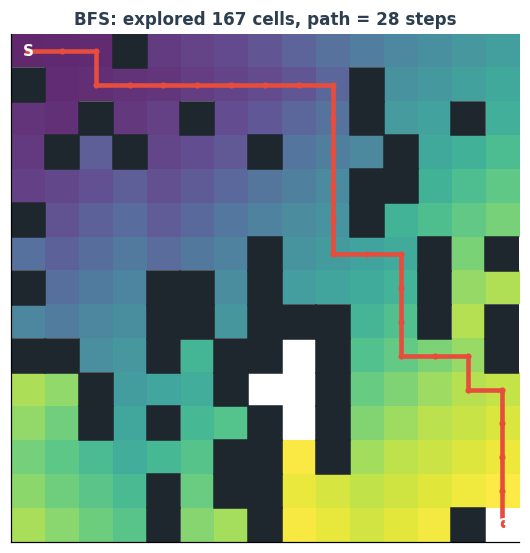

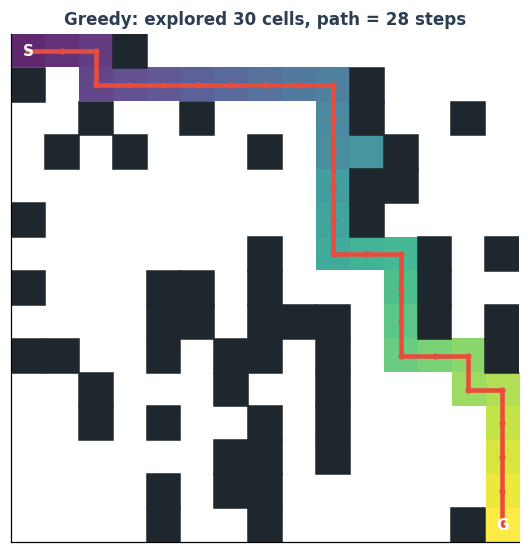

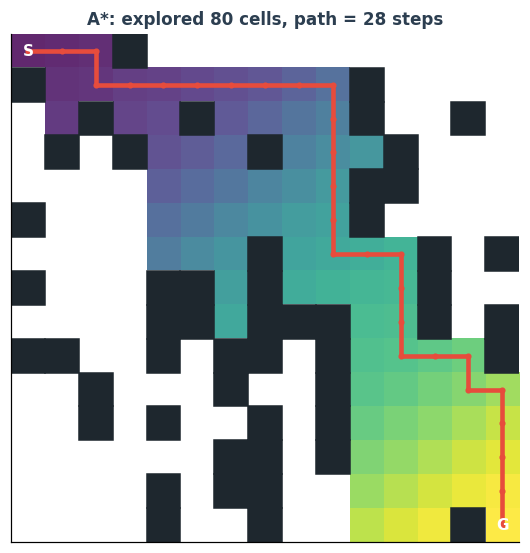

In [13]:
# Build the maze and compare BFS, Greedy and A* by their exploration pattern
def make_maze(size=15, wall_chance=0.28):
    for seed in range(200):
        rng = random.Random(seed)
        walls = {(r, c) for r in range(size) for c in range(size)
                 if rng.random() < wall_chance and (r, c) not in [(0, 0), (size - 1, size - 1)]}
        p = GridProblem(size, walls, (0, 0), (size - 1, size - 1))
        if bfs(p)["found"]:
            return p

maze = make_maze()
h_maze = lambda s: abs(s[0] - maze.goal[0]) + abs(s[1] - maze.goal[1])

def draw_maze(result):
    n = maze.size
    grid = np.full((n, n), np.nan)
    for k, (r, c) in enumerate(result["order"]):
        grid[r, c] = k / max(len(result["order"]) - 1, 1)
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(np.zeros((n, n)), cmap="gray_r", vmin=0, vmax=1)
    for (r, c) in maze.walls:
        ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, color="#1e272e"))
    ax.imshow(np.ma.masked_invalid(grid), cmap="viridis", alpha=0.85)
    path = result["path"]
    ax.plot([c for r, c in path], [r for r, c in path], color=RED, lw=3, marker="o", ms=3)
    ax.text(0, 0, "S", ha="center", va="center", color="white", fontweight="bold")
    ax.text(n - 1, n - 1, "G", ha="center", va="center", color="white", fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{result['algorithm']}: explored {result['expanded']} cells, path = {result['steps']} steps",
                 color=DARK, fontweight="bold", fontsize=11)
    plt.show()

maze_results = [bfs(maze), greedy(maze, h_maze), astar(maze, h_maze)]
maze_results[1]["algorithm"] = "Greedy"
for r in maze_results:
    draw_maze(r)

## 🎚️ Step 14: Weighted A\*: speed against perfection
> 💡 Change the formula to `f = g + w · h`. With `w = 1` it is plain A\*. With a bigger `w`, the algorithm **trusts the hint more**, behaving more like Greedy.
> Once `w > 1`, the heuristic effectively *over*-estimates, so the optimality guarantee is lost, but the search can get much faster. We try several weights on the maze and on a harder 8-puzzle.

 weight w  maze: path steps  maze: expanded  puzzle: solution moves  puzzle: expanded
      1.0                28              80                      18               259
      1.5                28              30                      18               207
      2.0                28              30                      18               279
      3.0                28              30                      18               589
      5.0                28              30                      30               211


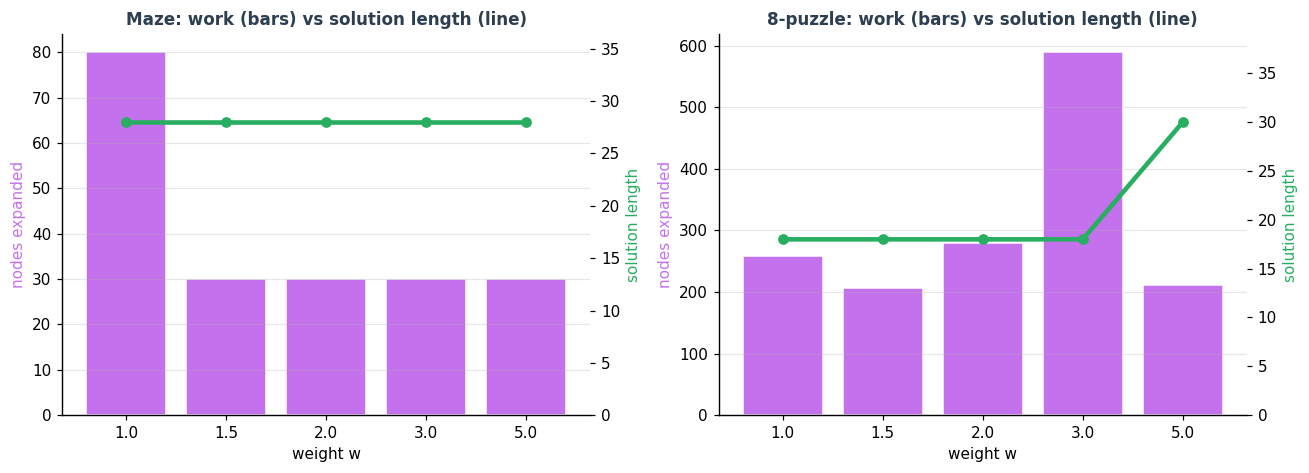

In [14]:
# Weighted A*: try several weights
hard = collected["≈ 17 moves"][0]                          # a harder puzzle (about 17 moves)
hard_problem = PuzzleProblem(hard, GOAL)

rows = []
for w in [1, 1.5, 2, 3, 5]:
    rm = astar(maze, h_maze, weight=w)
    rp = astar(hard_problem, h_manhattan, weight=w)
    rows.append({"weight w": w,
                 "maze: path steps": rm["steps"], "maze: expanded": rm["expanded"],
                 "puzzle: solution moves": rp["steps"], "puzzle: expanded": rp["expanded"]})
weighted = pd.DataFrame(rows)
print(weighted.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, (steps_col, exp_col, title) in zip(axes, [("maze: path steps", "maze: expanded", "Maze"),
                                                  ("puzzle: solution moves", "puzzle: expanded", "8-puzzle")]):
    ax.bar(weighted["weight w"].astype(str), weighted[exp_col], color=PURPLE, edgecolor="white")
    ax.set_xlabel("weight w"); ax.set_ylabel("nodes expanded", color=PURPLE)
    ax2 = ax.twinx()
    ax2.plot(weighted["weight w"].astype(str), weighted[steps_col], color=GREEN, marker="o", lw=3)
    ax2.set_ylabel("solution length", color=GREEN)
    ax2.set_ylim(0, max(weighted[steps_col]) * 1.3)
    ax.set_title(f"{title}: work (bars) vs solution length (line)", color=DARK, fontweight="bold", fontsize=11)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## ⚠️ Limitations of A\* and heuristic search

| Limitation | What it means | Who fixed it |
|---|---|---|
| ❌ **You must invent the heuristic** | A good `h` needs knowledge about the problem | Automatically learned heuristics, pattern databases (1990s) |
| ❌ **Memory** | A\* stores every generated state, which can run out of RAM before running out of time | IDA\* (1985), memory-bounded variants |
| ❌ **Admissibility is a promise** | If `h` over-estimates, the path may not be optimal | Check `h` carefully, or accept Weighted A\* trade-offs |
| ❌ **Still exponential** | A weak heuristic degrades towards blind search | Stronger heuristics, abstraction |
| ❌ **Needs a known goal and a known world** | Explicit states and costs | Planning languages, learning-based planning |

### 🧬 What it gave us
- The standard algorithm behind **GPS navigation, game AI pathfinding and robot motion planning**
- The idea of **heuristics**: using knowledge to avoid wasted work
- A clear theory: **admissible and consistent heuristics, optimality proofs**

## 📝 Summary
1. ✅ **Heuristic search** adds a hint `h(n)` to guide the search towards the goal.
2. ✅ **Greedy Best-First** uses only `h`: fast, but not optimal.
3. ✅ **A\*** uses `f = g + h`: optimal **if `h` is admissible**, and far fewer expansions than blind search.
4. ✅ **IDA\*** keeps the optimality with almost no memory.
5. ✅ A **more informed** heuristic (Manhattan over misplaced tiles) expands fewer nodes, which the experiment confirmed.
6. ✅ **Weighted A\*** trades optimality for speed.

## 🧪 Practice time
**Exercise 1.** Run A\* on the Romania map with `h = lambda city: 0`. Compare its expansions with UCS. What do you notice?

**Exercise 2.** Search from **Timisoara** to **Bucharest** with Greedy and A\*. Are the routes the same?

**Exercise 3.** Break admissibility: use `h = lambda city: 3 * straight_line[city]` on the map. Is the A\* route still the shortest (418 km)?

<details>
<summary>👀 Click to see the solutions</summary>

```python
# Exercise 1: h = 0 turns A* into Uniform-Cost Search
r0 = astar(map_problem, lambda city: 0)
print(r0["cost"], r0["expanded"], "vs UCS:", r_ucs["cost"], r_ucs["expanded"])   # same behaviour

# Exercise 2
p = MapProblem(roads, "Timisoara", "Bucharest")
for algo in (lambda: greedy(p, h_map), lambda: astar(p, h_map)):
    r = algo()
    print(r["algorithm"], " → ".join(r["path"]), r["cost"], "km")

# Exercise 3: an over-estimating hint can mislead A*
r3 = astar(map_problem, lambda city: 3 * straight_line[city])
print(r3["cost"], " → ".join(r3["path"]))   # may be longer than 418 km because h is no longer admissible
```
</details>

## ⏭️ What's next in AI-Genesis
The story continues with **games**: two players, each trying to beat the other. Next up: **Minimax and Alpha-Beta Pruning**. 🚀